# Modelos avançados — rodada de melhorias

Segunda rodada dos modelos avançados, **a partir do que a primeira rodada
(`05_modelos_avancados_kaggle.ipynb`) mostrou**:

- A avaliação em 5 partições deu STab (KS 0.535 ± 0.013) e TabKAN
  (0.531 ± 0.018) à frente de XGB/MLP/GB — são os candidatos com mais
  margem para melhorar.
- Em uma única partição o KS tem erro-padrão ≈ 0.02, então qualquer ganho
  aqui só conta se aparecer também na **avaliação robusta** (seção final).
- TabPFN e Mitra só foram bem com contexto **sem duplicatas** + correção de
  prior — as variantes novas partem dessa configuração.

**Auditoria:** nada da rodada anterior é reexecutado ou sobrescrito. Cada
experimento grava um `model_id` novo e descritivo (o nome diz o modelo e o
que mudou); `checar_id_novo` aborta se o ID já existir em `results/` do
repositório, e o push nunca substitui arquivo já versionado. Todas as
melhorias são **opções novas** nos wrappers de `src/churn_telecom/models/`,
com padrões que reproduzem exatamente a rodada anterior.

**No Kaggle, antes de rodar:** *Settings → Internet → On* e
*Accelerator → GPU*; depois **"Save Version" → "Save & Run All (Commit)"**.


In [1]:
#@title Setup (clona o repo e instala o pacote)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/jpbezerra/redes-neurais.git"   # ajuste se necessario
BRANCH   = "feat/churn"   # ajuste aqui se a branch de trabalho mudar
REPO_DIR = "redes-neurais"
SUBPATH  = "projeto/churn-telecom"

def _sh(cmd):
    print("$", cmd); subprocess.run(cmd, shell=True, check=False)

IN_COLAB  = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle")

if IN_COLAB or IN_KAGGLE:
    base = Path("/content") if IN_COLAB else Path("/kaggle/temp")  # fora de /kaggle/working: o clone nao entra no Output
    root = base / REPO_DIR
    if root.exists():
        _sh(f"cd {root} && git fetch origin {BRANCH} && git checkout {BRANCH} && git pull --ff-only origin {BRANCH}")
    else:
        _sh(f"git clone --branch {BRANCH} --single-branch {REPO_URL} {root}")
    PROJECT_ROOT = root / SUBPATH
    _sh(f"pip install -q -e {PROJECT_ROOT}")
else:
    PROJECT_ROOT = Path.cwd().parent

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# No Kaggle, tudo que for gerado vai para /kaggle/working/saida (so isso aparece
# no Output, em vez do repositorio inteiro).
OUT_DIR = Path("/kaggle/working/saida") if IN_KAGGLE else PROJECT_ROOT

DATA_DIR    = PROJECT_ROOT / "data"
RESULTS_DIR = OUT_DIR / "results"
TABLES_DIR  = OUT_DIR / "reports" / "tables"
for d in (DATA_DIR, RESULTS_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULTS_DIR :", RESULTS_DIR)


$ git clone --branch feat/churn --single-branch https://github.com/jpbezerra/redes-neurais.git /kaggle/temp/redes-neurais


Cloning into '/kaggle/temp/redes-neurais'...
Updating files: 100% (955/955), done.


$ pip install -q -e /kaggle/temp/redes-neurais/projeto/churn-telecom
PROJECT_ROOT: /kaggle/temp/redes-neurais/projeto/churn-telecom
RESULTS_DIR : /kaggle/working/saida/results


## Instalação dos modelos avançados

In [2]:
!pip install -q tabpfn pykan tabkan
!pip install -q "autogluon.tabular[mitra]"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 2.8 MB/s eta 0:00:00


## Preparação dos dados

Mesma partição da rodada anterior (`SEED = 0`), então as probabilidades
já salvas (`predicoes.npz`) dos modelos antigos se alinham linha a linha com
as dos novos — dá para combiná-los em ensemble sem retreinar nada.


In [3]:
import torch
import joblib
import numpy as np
import pandas as pd

from churn_telecom.data import load_raw, split_three_stage, assert_sem_vazamento
from churn_telecom.features import Preprocessor
from churn_telecom.metrics import full_report
from churn_telecom.checkpointing import save_run, load_all_metadata
from churn_telecom.ensemble import corrigir_prior, salvar_predicoes, media_probabilidades

SEED = 0
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

df = load_raw(DATA_DIR)
split = split_three_stage(df, seed=SEED)
assert_sem_vazamento(split)
df_train, df_val, df_test = df.iloc[split.train_idx], df.iloc[split.val_idx], df.iloc[split.test_idx]

prep = Preprocessor().fit(df_train)
X_train, cols = prep.transform(df_train)
X_val, _ = prep.transform(df_val)
X_test, _ = prep.transform(df_test)
y_train = prep.transform_target(df_train)
y_val = prep.transform_target(df_val)
y_test = prep.transform_target(df_test)

# Versao SEM linhas duplicadas do treino (mesmas linhas originais, sem oversampling).
# TabPFN/Mitra fazem in-context learning: linhas repetidas viram memorizacao e
# distorcem a calibracao, entao eles tambem sao treinados nesta versao.
df_train_nat = df.iloc[split.train_no_oversample_idx]
X_train_nat, _ = prep.transform(df_train_nat)
y_train_nat = prep.transform_target(df_train_nat)
PRIOR_NAT = float(y_train_nat.mean())

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")
print(f"X_train_nat (sem duplicatas): {X_train_nat.shape} | prior de churn: {PRIOR_NAT:.3f}")


device: cuda
Baixando CSV de https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv ...
CSV salvo em /kaggle/temp/redes-neurais/projeto/churn-telecom/data/telco_customer_churn.csv
X_train: (5174, 40) | X_val: (2588, 40) | X_test: (1761, 40)
X_train_nat (sem duplicatas): (3521, 40) | prior de churn: 0.265


## Utilitários

Igual à rodada anterior (`rodar` isola falhas por modelo), mais:

- `checar_id_novo`: aborta o experimento se o `model_id` já existir no
  Output **ou** em `results/` do repositório clonado (nunca sobrescreve
  a auditoria);
- `salvar`: grava também KS/AUROC de **validação** no `metadata.json`, para
  que a escolha entre variantes (feita só na validação) fique registrada.


In [4]:
import traceback

from churn_telecom.metrics import auroc
from churn_telecom.ensemble import media_logits

FALHAS = {}
RESULTS_REPO = PROJECT_ROOT / "results"   # resultados ja versionados (rodadas anteriores)

def checar_id_novo(model_id):
    for base in (RESULTS_DIR, RESULTS_REPO):
        if (base / model_id).exists():
            raise FileExistsError(f"{model_id} ja existe em {base} — use um ID novo (auditoria).")

def metricas_validacao(p_val):
    return {"ks_validacao": full_report(y_val, p_val)["ks"], "auroc_validacao": auroc(y_val, p_val)}

def salvar(model_id, prever, corrigir=None, **kwargs):
    # prever(X) -> probabilidades; corrigir ajusta o prior (TabPFN/Mitra sem duplicatas)
    pv, pt = prever(X_val), prever(X_test)
    if corrigir is not None:
        pv, pt = corrigir(pv), corrigir(pt)
    metricas = full_report(y_test, pt)
    val = metricas_validacao(pv)
    print(model_id, "| val:", {k: round(v, 4) for k, v in val.items()},
          "| teste:", {k: round(metricas[k], 4) for k in ("ks", "auroc", "recall", "precision")})
    save_run(RESULTS_DIR, model_id, metrics=metricas, dataset_info={"metricas_validacao": val}, **kwargs)
    salvar_predicoes(RESULTS_DIR, model_id, pv, pt)
    return val

# Etapas da rodada 2 (melhorias manuais) — ja executadas e versionadas em results/.
# Num novo "Run All" elas sao puladas; so as etapas novas rodam.
ETAPAS_RODADA_2 = {
    "stab_churn_dim32_depth2_heads4_embfeature_parada_auroc_plateau",
    "stab_churn_dim64_depth3_heads8_embfeature_parada_auroc_plateau", "stab_bagging",
    "tabkan_churn_chebyshev_largura10_grau3_parada_auroc_plateau",
    "tabkan_churn_chebyshev_largura32_grau3_wd1e-4_parada_auroc_plateau",
    "kan", "tabpfn", "mitra", "xgb", "ensembles", "avaliacao_robusta",
}
RODADA_2_CONCLUIDA = (PROJECT_ROOT / "reports" / "tables" / "avaliacao_robusta_modelos_melhorados_resumo.csv").exists()

# Idem para a rodada 3 (busca Optuna).
ETAPAS_RODADA_3 = {f"optuna_{a}" for a in ("mlp", "gb", "xgb", "stab", "tabkan", "kan")} | {
    "grafico_importancias", "avaliacao_robusta_optuna"}
RODADA_3_CONCLUIDA = (PROJECT_ROOT / "reports" / "tables" / "avaliacao_robusta_optuna_resumo.csv").exists()

def rodar(nome, fn):
    if RODADA_2_CONCLUIDA and nome in ETAPAS_RODADA_2:
        print(f"[pulado] {nome} (rodada 2 ja executada e versionada)")
        return
    if RODADA_3_CONCLUIDA and nome in ETAPAS_RODADA_3:
        print(f"[pulado] {nome} (rodada 3 ja executada e versionada)")
        return
    try:
        fn()
        print(f"[ok] {nome}")
    except Exception as e:
        FALHAS[nome] = f"{type(e).__name__}: {e}"
        print(f"[FALHOU] {nome}: {type(e).__name__}: {e}")
        traceback.print_exc()

VALIDACAO = {}   # model_id -> metricas de validacao (para escolher variantes sem olhar o teste)


## STab — melhorias de treino e de embedding

Rodada anterior: `stab_churn_dim32_depth2_heads4_oversample` (embedding
compartilhado + posicional, parada pela cross-entropy de validação).

Mudanças testadas (opções novas em `models/stab.py`):

- **embedding por feature** (`W_i·x + b_i`, como no FT-Transformer): cada
  feature ganha sua própria projeção, em vez de uma projeção única
  diferenciada só por um vetor posicional somado;
- **parada e escolha da época pelo AUROC de validação** — o KS só depende
  da ordem dos scores, então o critério de ranking é mais alinhado do que
  a cross-entropy (que também premia calibração);
- **ReduceLROnPlateau** + gradient clipping + `weight_decay` maior.

Duas capacidades: a mesma do original e uma maior. A melhor (pelo AUROC de
**validação**) é depois re-treinada com 5 sementes e as probabilidades são
médias (*bagging de sementes*) — redes pequenas em dados tabulares variam
bastante entre sementes, e a média reduz essa variância.


In [5]:
from churn_telecom.models.stab import STabHyperparams, treinar_stab, prever_stab

MELHORIAS_TREINO = dict(embedding="por_feature", early_stop_metric="val_auroc",
                        scheduler="plateau", max_grad_norm=1.0, patience=20)

CONFIGS_STAB = {
    "stab_churn_dim32_depth2_heads4_embfeature_parada_auroc_plateau":
        STabHyperparams(dim=32, depth=2, heads=4, attn_dropout=0.1, ff_dropout=0.1, lr=1e-3,
                        weight_decay=1e-4, batch_size=64, max_epochs=200, seed=SEED, **MELHORIAS_TREINO),
    "stab_churn_dim64_depth3_heads8_embfeature_parada_auroc_plateau":
        STabHyperparams(dim=64, depth=3, heads=8, attn_dropout=0.15, ff_dropout=0.15, lr=5e-4,
                        weight_decay=1e-4, batch_size=128, max_epochs=200, seed=SEED, **MELHORIAS_TREINO),
}

def experimento_stab(model_id, hp):
    checar_id_novo(model_id)
    modelo, historico = treinar_stab(X_train, y_train, X_val, y_val, hp, device=device, verbose=True)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_stab(modelo, X, device=device),
        framework="PyTorch (STab — implementacao propria)", hyperparameters=hp.__dict__,
        architecture={"dim": hp.dim, "depth": hp.depth, "heads": hp.heads, "embedding": hp.embedding},
        history=historico, notes="STab com embedding por feature, parada pelo AUROC de validacao e ReduceLROnPlateau.",
        save_model_fn=lambda d: torch.save(modelo.state_dict(), d / "model.pt"))

for mid, hp in CONFIGS_STAB.items():
    rodar(mid, lambda mid=mid, hp=hp: experimento_stab(mid, hp))


[pulado] stab_churn_dim32_depth2_heads4_embfeature_parada_auroc_plateau (rodada 2 ja executada e versionada)
[pulado] stab_churn_dim64_depth3_heads8_embfeature_parada_auroc_plateau (rodada 2 ja executada e versionada)


In [6]:
from dataclasses import replace

N_SEMENTES_BAGGING = 5

def melhor_por_validacao(ids):
    candidatos = [i for i in ids if i in VALIDACAO]
    if not candidatos:
        raise RuntimeError(f"nenhuma variante concluiu: {ids}")
    return max(candidatos, key=lambda i: VALIDACAO[i]["auroc_validacao"])

def experimento_stab_bagging():
    base_id = melhor_por_validacao(CONFIGS_STAB)
    model_id = f"{base_id}_bagging{N_SEMENTES_BAGGING}sementes"
    checar_id_novo(model_id)
    print("config escolhida pela validacao:", base_id)
    modelos = []
    for k in range(N_SEMENTES_BAGGING):
        hp = replace(CONFIGS_STAB[base_id], seed=SEED + k)
        m, _ = treinar_stab(X_train, y_train, X_val, y_val, hp, device=device)
        modelos.append(m)
    prever = lambda X: np.mean([prever_stab(m, X, device=device) for m in modelos], axis=0)
    def salvar_pesos(d):
        for k, m in enumerate(modelos):
            torch.save(m.state_dict(), d / f"model_seed{SEED + k}.pt")
    VALIDACAO[model_id] = salvar(
        model_id, prever, framework="PyTorch (STab — implementacao propria)",
        hyperparameters={**CONFIGS_STAB[base_id].__dict__, "seeds": [SEED + k for k in range(N_SEMENTES_BAGGING)]},
        architecture={"config_base": base_id}, save_model_fn=salvar_pesos,
        notes=f"Media das probabilidades de {N_SEMENTES_BAGGING} sementes da config {base_id} (escolhida pelo AUROC de validacao).")

rodar("stab_bagging", experimento_stab_bagging)


[pulado] stab_bagging (rodada 2 ja executada e versionada)


## TabKAN — mesmas melhorias de treino, mais largura

Rodada anterior: `tabkan_churn_chebyshev_largura10_grau3_oversample`.
Aqui: parada pelo AUROC de validação + ReduceLROnPlateau + clipping, na
mesma largura e numa camada oculta mais larga com `weight_decay` maior.


In [7]:
from churn_telecom.models.tabkan import TabKANHyperparams, treinar_tabkan, prever_tabkan

MELHORIAS_TABKAN = dict(early_stop_metric="val_auroc", scheduler="plateau", max_grad_norm=1.0, patience=20)

CONFIGS_TABKAN = {
    "tabkan_churn_chebyshev_largura10_grau3_parada_auroc_plateau":
        TabKANHyperparams(hidden_width=10, degree=3, lr=1e-3, weight_decay=1e-5, batch_size=64,
                          max_epochs=300, seed=SEED, **MELHORIAS_TABKAN),
    "tabkan_churn_chebyshev_largura32_grau3_wd1e-4_parada_auroc_plateau":
        TabKANHyperparams(hidden_width=32, degree=3, lr=1e-3, weight_decay=1e-4, batch_size=64,
                          max_epochs=300, seed=SEED, **MELHORIAS_TABKAN),
}

def experimento_tabkan(model_id, hp):
    checar_id_novo(model_id)
    modelo, historico = treinar_tabkan(X_train, y_train, X_val, y_val, hp, device=device, verbose=True)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_tabkan(modelo, X, device=device),
        framework="tabkan (ChebyshevKAN)", hyperparameters=hp.__dict__,
        architecture={"hidden_width": hp.hidden_width, "degree": hp.degree}, history=historico,
        notes="TabKAN com parada pelo AUROC de validacao e ReduceLROnPlateau.",
        save_model_fn=lambda d: torch.save(modelo.state_dict(), d / "model.pt"))

for mid, hp in CONFIGS_TABKAN.items():
    rodar(mid, lambda mid=mid, hp=hp: experimento_tabkan(mid, hp))


[pulado] tabkan_churn_chebyshev_largura10_grau3_parada_auroc_plateau (rodada 2 ja executada e versionada)
[pulado] tabkan_churn_chebyshev_largura32_grau3_wd1e-4_parada_auroc_plateau (rodada 2 ja executada e versionada)


## KAN (pykan) — grade mais fina e regularização

Rodada anterior: `kan_churn_largura8_grid3_k3_oversample` (o mais fraco
dos modelos neurais, KS 0.506). Grade de splines mais fina (`grid=5`),
`weight_decay` e o mesmo critério de parada/scheduler das outras redes.


In [8]:
from churn_telecom.models.kan import KANHyperparams, treinar_kan, prever_kan

def experimento_kan():
    model_id = "kan_churn_largura8_grid5_k3_wd1e-4_parada_auroc_plateau"
    checar_id_novo(model_id)
    hp = KANHyperparams(hidden_width=8, grid=5, k=3, lr=3e-3, batch_size=128, max_epochs=150, patience=15,
                        weight_decay=1e-4, early_stop_metric="val_auroc", scheduler="plateau", seed=SEED)
    modelo, historico = treinar_kan(X_train, y_train, X_val, y_val, hp, device=device, verbose=True)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_kan(modelo, X, device=device),
        framework="pykan (KAN)", hyperparameters=hp.__dict__,
        architecture={"hidden_width": hp.hidden_width, "grid": hp.grid, "k": hp.k},
        history=pd.DataFrame(historico), notes="KAN com grid=5, weight decay e parada pelo AUROC de validacao.",
        save_model_fn=lambda d: torch.save(modelo.state_dict(), d / "model.pt"))

rodar("kan", experimento_kan)


[pulado] kan (rodada 2 ja executada e versionada)


## TabPFN v2 — contexto sem duplicatas, ensemble interno maior

Rodada anterior: melhor configuração foi
`tabpfn_v2_churn_contexto_original_prior_corrigido` (16 estimadores
internos). Aqui: 32 estimadores (mais permutações de features/classes no
ensemble interno do TabPFN — mais estável, sem risco de overfitting porque
não há treino).


In [9]:
from churn_telecom.models.tabpfn import TabPFNHyperparams, treinar_tabpfn, prever_tabpfn

def experimento_tabpfn():
    model_id = "tabpfn_v2_churn_contexto_original_prior_corrigido_32estimadores"
    checar_id_novo(model_id)
    hp = TabPFNHyperparams(device=device, n_estimators=32, versao="v2", seed=SEED)
    modelo = treinar_tabpfn(X_train_nat, y_train_nat, hp)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_tabpfn(modelo, X), corrigir=lambda p: corrigir_prior(p, PRIOR_NAT),
        framework="TabPFN v2",
        hyperparameters={**hp.__dict__, "n_linhas_contexto": len(X_train_nat), "prior_corrigido": PRIOR_NAT},
        notes="TabPFN v2, contexto sem duplicatas, 32 estimadores internos.",
        save_model_fn=lambda d: None)

rodar("tabpfn", experimento_tabpfn)


[pulado] tabpfn (rodada 2 ja executada e versionada)


## Mitra — contexto sem duplicatas, ensemble interno e mais fine-tuning

Rodada anterior: `mitra_churn_contexto_original_prior_corrigido` (KS 0.533,
o melhor modelo isolado na partição única), com os padrões do AutoGluon
(`n_estimators=1`, fine-tuning de 50 passos). Aqui: 4 estimadores internos
e 100 passos de fine-tuning.


In [10]:
from churn_telecom.models.mitra import MitraHyperparams, treinar_mitra, prever_mitra, salvar_mitra

def experimento_mitra():
    model_id = "mitra_churn_contexto_original_prior_corrigido_4estimadores_finetune100"
    checar_id_novo(model_id)
    hp = MitraHyperparams(time_limit_segundos=1200, num_gpus=1 if device == "cuda" else 0, seed=SEED,
                          n_estimators=4, fine_tune_steps=100)
    preditor = treinar_mitra(X_train_nat, y_train_nat, cols, hp, path=f"/kaggle/temp/ag_{model_id}")
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: prever_mitra(preditor, X, cols), corrigir=lambda p: corrigir_prior(p, PRIOR_NAT),
        framework="AutoGluon (extra [mitra])",
        hyperparameters={**hp.__dict__, "n_linhas_contexto": len(X_train_nat), "prior_corrigido": PRIOR_NAT},
        notes="Mitra, contexto sem duplicatas, 4 estimadores internos, 100 passos de fine-tuning.",
        save_model_fn=lambda d: salvar_mitra(preditor, d / "autogluon_predictor"))

rodar("mitra", experimento_mitra)


[pulado] mitra (rodada 2 ja executada e versionada)


## XGBoost — mais árvores com early stopping na validação

Os baselines de boosting usam 100 árvores fixas, e a busca Optuna anterior
sobreajustou à validação (20 trials × 5 hiperparâmetros). Aqui não há
busca: uma configuração regularizada padrão de mercado (lr baixo,
subsample/colsample 0.8, `min_child_weight`, L2) e **só o número de
árvores** é escolhido pela validação, via early stopping no AUROC.


In [11]:
from churn_telecom.models.boosting import XGBoostHyperparams, treinar_xgboost

HP_XGB_MELHORADO = XGBoostHyperparams(learning_rate=0.03, n_estimators=2000, max_depth=4, subsample=0.8,
                                      colsample_bytree=0.8, min_child_weight=5, reg_lambda=5.0,
                                      eval_metric="auc", early_stopping_rounds=100, seed=SEED)

def experimento_xgb():
    model_id = "xgb_churn_lr003_prof4_sub08_col08_earlystop_auc_validacao"
    checar_id_novo(model_id)
    modelo = treinar_xgboost(X_train, y_train, HP_XGB_MELHORADO, X_val=X_val, y_val=y_val)
    print("arvores escolhidas pela validacao:", modelo.best_iteration + 1)
    VALIDACAO[model_id] = salvar(
        model_id, lambda X: modelo.predict_proba(X)[:, 1], framework="XGBoost",
        hyperparameters={**HP_XGB_MELHORADO.__dict__, "n_arvores_escolhidas": int(modelo.best_iteration + 1)},
        notes="XGBoost regularizado; numero de arvores por early stopping no AUROC de validacao.",
        save_model_fn=lambda d: joblib.dump(modelo, d / "model.joblib"))

rodar("xgb", experimento_xgb)


[pulado] xgb (rodada 2 ja executada e versionada)


## Ensembles — modelos novos + modelos já salvos da rodada anterior

A partição é a mesma, então as `predicoes.npz` já versionadas da rodada
anterior entram como candidatas sem retreino. Mudanças em relação aos
ensembles anteriores:

- **média no espaço logit** (média geométrica das odds) em vez da média de
  probabilidades — modelos com escalas diferentes (prior corrigido vs.
  treino balanceado) não são achatados;
- seleção dos membros pelo **AUROC de validação** (menos ruidoso que o KS
  de validação), com `k` fixado antes de olhar qualquer resultado.
  O teste não participa da escolha.


In [12]:
def construir_ensembles():
    fontes = {}
    for base in (RESULTS_REPO, RESULTS_DIR):   # anteriores + desta rodada
        for d in sorted(base.iterdir()):
            if (d / "predicoes.npz").exists() and not d.name.startswith("ensemble_"):
                fontes[d.name] = d / "predicoes.npz"
    P = {i: np.load(f) for i, f in fontes.items()}
    for i in P:
        assert len(P[i]["p_val"]) == len(y_val) and len(P[i]["p_test"]) == len(y_test), f"{i}: particao diferente"
    auc_val = {i: auroc(y_val, P[i]["p_val"]) for i in P}
    ordem = sorted(P, key=lambda i: -auc_val[i])
    print("AUROC de validacao:", {i: round(auc_val[i], 4) for i in ordem})
    novos = [i for i in ordem if (RESULTS_DIR / i).exists()]
    for model_id, membros in [("ensemble_media_logit_top5_validacao_churn", ordem[:5]),
                              ("ensemble_media_logit_modelos_melhorados_churn", novos)]:
        checar_id_novo(model_id)
        if len(membros) < 2:
            print(f"{model_id}: menos de 2 membros, pulando"); continue
        pv = media_logits([P[m]["p_val"] for m in membros])
        pt = media_logits([P[m]["p_test"] for m in membros])
        metricas = full_report(y_test, pt)
        val = metricas_validacao(pv)
        print(model_id, membros, "| val:", {k: round(v, 4) for k, v in val.items()},
              "| teste:", {k: round(metricas[k], 4) for k in ("ks", "auroc", "recall", "precision")})
        save_run(RESULTS_DIR, model_id, framework="media no espaco logit", hyperparameters={"membros": membros},
                 metrics=metricas, dataset_info={"metricas_validacao": val},
                 notes="Ensemble por media dos logits; membros escolhidos pelo AUROC de validacao.",
                 save_model_fn=lambda d: None)
        salvar_predicoes(RESULTS_DIR, model_id, pv, pt)

rodar("ensembles", construir_ensembles)


[pulado] ensembles (rodada 2 ja executada e versionada)


## Avaliação robusta (5 partições) — antigo vs. melhorado, lado a lado

Mesmas 5 sementes de partição da rodada anterior (0–4). As versões
**originais** de STab/TabKAN/XGB são re-treinadas aqui também, para que a
comparação seja pareada (mesma partição, mesmo hardware) — os números da
rodada anterior continuam intactos em
`reports/tables/avaliacao_robusta_resumo_kaggle.csv`.

A melhoria só deve ser considerada real se `ks_mean` subir com folga em
relação ao desvio (`ks_std`).


In [13]:
from churn_telecom.robustez import avaliar_multiplas_particoes, resumir
from churn_telecom.ensemble import media_probabilidades
from churn_telecom.models.boosting import GradientBoostingHyperparams, treinar_gradient_boosting

STAB_ESCOLHIDO = melhor_por_validacao(CONFIGS_STAB) if any(i in VALIDACAO for i in CONFIGS_STAB) else None
TABKAN_ESCOLHIDO = melhor_por_validacao(CONFIGS_TABKAN) if any(i in VALIDACAO for i in CONFIGS_TABKAN) else None
print("STab escolhido:", STAB_ESCOLHIDO, "| TabKAN escolhido:", TABKAN_ESCOLHIDO)

def f_stab_original(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_stab(Xtr, ytr, Xva, yva, STabHyperparams(seed=sd), device=device)
    return lambda X: prever_stab(m, X, device=device)

def f_stab_melhorado(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_stab(Xtr, ytr, Xva, yva, replace(CONFIGS_STAB[STAB_ESCOLHIDO], seed=sd), device=device)
    return lambda X: prever_stab(m, X, device=device)

def f_stab_melhorado_bagging(Xtr, ytr, Xva, yva, sd):
    ms = [treinar_stab(Xtr, ytr, Xva, yva, replace(CONFIGS_STAB[STAB_ESCOLHIDO], seed=100 * sd + k),
                       device=device)[0] for k in range(N_SEMENTES_BAGGING)]
    return lambda X: np.mean([prever_stab(m, X, device=device) for m in ms], axis=0)

def f_tabkan_original(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_tabkan(Xtr, ytr, Xva, yva, TabKANHyperparams(seed=sd), device=device, verbose=False)
    return lambda X: prever_tabkan(m, X, device=device)

def f_tabkan_melhorado(Xtr, ytr, Xva, yva, sd):
    m, _ = treinar_tabkan(Xtr, ytr, Xva, yva, replace(CONFIGS_TABKAN[TABKAN_ESCOLHIDO], seed=sd),
                          device=device, verbose=False)
    return lambda X: prever_tabkan(m, X, device=device)

def f_xgb_original(Xtr, ytr, Xva, yva, sd):
    m = treinar_xgboost(Xtr, ytr, XGBoostHyperparams(seed=sd))
    return lambda X: m.predict_proba(X)[:, 1]

def f_xgb_melhorado(Xtr, ytr, Xva, yva, sd):
    m = treinar_xgboost(Xtr, ytr, replace(HP_XGB_MELHORADO, seed=sd), X_val=Xva, y_val=yva)
    return lambda X: m.predict_proba(X)[:, 1]

def avaliacao_robusta():
    fabricas = {"stab_original": f_stab_original, "tabkan_original": f_tabkan_original,
                "xgb_original": f_xgb_original, "xgb_melhorado": f_xgb_melhorado}
    if STAB_ESCOLHIDO:
        fabricas.update({"stab_melhorado": f_stab_melhorado, "stab_melhorado_bagging": f_stab_melhorado_bagging})
    if TABKAN_ESCOLHIDO:
        fabricas["tabkan_melhorado"] = f_tabkan_melhorado
    ensembles = {
        "ensemble_media_prob_originais": (["stab_original", "tabkan_original", "xgb_original"], media_probabilidades),
        "ensemble_media_logit_melhorados": (["stab_melhorado_bagging", "tabkan_melhorado", "xgb_melhorado"], media_logits),
    }
    longo = avaliar_multiplas_particoes(df, fabricas, seeds=range(5), incluir_ensemble=False, ensembles=ensembles)
    longo.to_csv(TABLES_DIR / "avaliacao_robusta_modelos_melhorados_por_particao.csv", index=False)
    resumo = resumir(longo)
    resumo.to_csv(TABLES_DIR / "avaliacao_robusta_modelos_melhorados_resumo.csv", index=False)
    print(resumo.round(4).to_string())

rodar("avaliacao_robusta", avaliacao_robusta)


STab escolhido: None | TabKAN escolhido: None
[pulado] avaliacao_robusta (rodada 2 ja executada e versionada)


## Comparação — rodada anterior vs. esta rodada (partição única)

Lembre que, numa partição só, diferenças de KS abaixo de ~0.02 estão
dentro do ruído; a tabela da avaliação robusta acima é a que decide.


In [14]:
if RODADA_2_CONCLUIDA:
    print("[pulado] comparacao da rodada 2 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "modelos_melhorados_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")

    antes = load_all_metadata(RESULTS_REPO).assign(rodada="anterior")
    agora = load_all_metadata(RESULTS_DIR).assign(rodada="melhorias")
    cols = ["rodada", "model_id", "metrics.ks", "metrics.auroc", "metrics.recall", "metrics.precision"]
    comparacao = pd.concat([antes, agora], ignore_index=True)
    comparacao = comparacao[[c for c in cols if c in comparacao.columns]].sort_values("metrics.ks", ascending=False)
    comparacao.to_csv(TABLES_DIR / "modelos_melhorados_comparacao_particao_unica.csv", index=False)
    display(comparacao.reset_index(drop=True))


[pulado] comparacao da rodada 2 (ja versionada)


## Salvando os resultados

Igual à rodada anterior (zip no Output + push opcional com o segredo
`GITHUB_TOKEN`), mas para a branch **`results/churn-modelos-melhorados`** e
com uma trava extra: se algum arquivo já existir no repositório clonado, o
push é abortado em vez de sobrescrever. Localmente:
`git fetch origin results/churn-modelos-melhorados` e
`git checkout origin/results/churn-modelos-melhorados -- projeto/churn-telecom/results projeto/churn-telecom/reports/tables`.


In [15]:
import shutil

FIGURES_DIR = OUT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

LIMITE_MB = 20   # GitHub rejeita >100 MB por arquivo (o preditor do Mitra tem ~290 MB)

def salvar_saida(RESULTS_BRANCH, nome_zip, mensagem):
    if not IN_KAGGLE:
        return
    zip_path = shutil.make_archive(f"/kaggle/working/{nome_zip}", "zip", OUT_DIR)
    print("Zip gerado:", zip_path)

    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception:
        token = None

    if not token:
        print("Sem segredo GITHUB_TOKEN: pulando o push (baixe o zip pelo Output).")
    else:
        try:
            def copiar_pequenos(origem, destino, pulados):
                for f in Path(origem).rglob("*"):
                    if not f.is_file():
                        continue
                    if f.stat().st_size > LIMITE_MB * 1024 * 1024:
                        pulados.append(f"{f.relative_to(origem)} ({f.stat().st_size / 1e6:.0f} MB)")
                        continue
                    alvo = Path(destino) / f.relative_to(origem)
                    if alvo.exists():   # auditoria: nunca sobrescreve resultado/tabela ja versionado
                        print(f"  ja versionado, mantido como esta: {alvo.relative_to(PROJECT_ROOT)}")
                        continue
                    alvo.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(f, alvo)

            pulados = []
            copiar_pequenos(RESULTS_DIR, PROJECT_ROOT / "results", pulados)
            copiar_pequenos(TABLES_DIR, PROJECT_ROOT / "reports" / "tables", pulados)
            copiar_pequenos(FIGURES_DIR, PROJECT_ROOT / "reports" / "figures", pulados)
            if pulados:
                print(f"Arquivos > {LIMITE_MB} MB NAO enviados ao GitHub (estao no zip):")
                for x in pulados:
                    print("  -", x)

            def git(*args):
                r = subprocess.run(["git", "-C", str(root), "-c", "user.name=kaggle-run",
                                    "-c", "user.email=kaggle-run@users.noreply.github.com", *args],
                                   capture_output=True, text=True)
                saida = (r.stdout + r.stderr).replace(token, "***")
                if r.returncode != 0:
                    raise RuntimeError(f"git {args[0]} falhou: {saida}")
                return saida

            git("checkout", "-B", RESULTS_BRANCH)
            git("add", "-f", f"{SUBPATH}/results", f"{SUBPATH}/reports/tables", f"{SUBPATH}/reports/figures")
            git("commit", "-m", mensagem)
            url = REPO_URL.replace("https://", f"https://x-access-token:{token}@")
            git("push", "--force", url, f"HEAD:refs/heads/{RESULTS_BRANCH}")
            print(f"Resultados enviados para a branch {RESULTS_BRANCH}.")
        except Exception as e:
            print("Push falhou (o zip continua valido):", str(e)[:600])

if RODADA_2_CONCLUIDA:
    print("[pulado] salvamento da rodada 2 (ja versionada) — a rodada Optuna salva no fim do notebook")
else:
    salvar_saida("results/churn-modelos-melhorados", "results_churn_modelos_melhorados",
                 "results: saidas do notebook de modelos melhorados (Kaggle)")


[pulado] salvamento da rodada 2 (ja versionada) — a rodada Optuna salva no fim do notebook


# Rodada 3 — busca de hiperparâmetros com Optuna, procedimento único para todos

A rodada 2 (acima) mostrou que **ajustes feitos à mão não mudam o resultado
de forma mensurável**: na avaliação em 5 partições ficou tudo entre KS
0.528 e 0.535, com desvio ≈ 0.015. Esta rodada troca a intuição por uma
busca sistemática e responde à pergunta da apresentação: *quais parâmetros
influenciam de verdade?*

**Procedimento — o mesmo para todos os algoritmos treináveis**
(MLP, Gradient Boosting, XGBoost, STab, TabKAN, KAN):

1. mesma partição (`SEED = 0`), mesmo treino com oversampling, mesma validação;
2. **Optuna** com o mesmo orçamento (`N_TRIALS`), o mesmo amostrador (TPE,
   semente fixa) e o **mesmo objetivo: AUROC de validação**. O KS continua sendo
   a métrica reportada, mas olha um único ponto da curva e é mais ruidoso:
   a busca anterior otimizada por KS de validação sobreajustou à validação
   (KS 0.571 na validação → 0.510 no teste);
3. redes neurais: early stopping pelo **mesmo critério** (AUROC de validação);
   XGBoost: número de árvores por early stopping no AUROC de validação;
4. o teste só é usado uma vez, no modelo final de cada busca;
5. **importância dos hiperparâmetros** (fANOVA do Optuna) por algoritmo:
   mostra quais parâmetros explicam a variação do AUROC entre os trials;
6. **avaliação robusta em 5 partições**: configuração padrão vs. melhor do
   Optuna para cada algoritmo, com o mesmo procedimento.

**Codificação por família (apontamento do professor):** modelos de árvore
(GB, XGBoost) **não** usam a mesma codificação das redes. Redes recebem
z-score + one-hot (40 colunas); árvores recebem as numéricas na escala original
e uma coluna de código ordinal por variável categórica (19 colunas) —
`Preprocessor(modo="arvores")`. A avaliação robusta inclui GB/XGBoost
padrão nas duas codificações, para medir o efeito disso isoladamente.

TabPFN e Mitra ficam fora da busca: são pré-treinados (in-context learning),
não têm hiperparâmetros de treino; seus resultados estão nas rodadas 1–2.

*As células 7, 26 e 28 acima ganharam só uma trava para pular a rodada 2 num
novo "Run All"; as saídas exibidas nelas são da execução original da rodada 2
(versão exata do código executado no commit `c2c25ad`).*


In [16]:
!pip install -q optuna

In [17]:
import optuna
from dataclasses import asdict, replace
from churn_telecom.models.mlp import MLPHyperparams, treinar_mlp
from churn_telecom.models.boosting import GradientBoostingHyperparams, treinar_gradient_boosting

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30

# Mesma particao, duas codificacoes: cada familia recebe a sua.
prep_arv = Preprocessor(modo="arvores").fit(df_train)
X_train_arv, cols_arv = prep_arv.transform(df_train)
X_val_arv, _ = prep_arv.transform(df_val)
X_test_arv, _ = prep_arv.transform(df_test)
DADOS = {"neural": (X_train, X_val, X_test), "arvores": (X_train_arv, X_val_arv, X_test_arv)}
CODIFICACAO = {"neural": "zscore_onehot", "arvores": "ordinal"}
print("neural:", X_train.shape, "| arvores:", X_train_arv.shape)

BUSCAS = {}   # algoritmo -> {"study", "model_id", "hp", "modo"}

def otimizar(algoritmo, sugerir, treinar, framework, modo="neural"):
    """Procedimento unico: N_TRIALS de TPE maximizando AUROC de validacao,
    salva trials + importancias, retreina o melhor e avalia no teste (uma vez).
    `sugerir(trial) -> hp`; `treinar(hp, Xtr, ytr, Xva, yva) -> (prever, salvar_modelo, historico)`."""
    model_id = f"{algoritmo}_churn_optuna{N_TRIALS}trials_auroc_validacao_{CODIFICACAO[modo]}"
    checar_id_novo(model_id)
    Xtr, Xva, Xte = DADOS[modo]

    def objetivo(trial):
        prever, _, _ = treinar(sugerir(trial), Xtr, y_train, Xva, y_val)
        return auroc(y_val, prever(Xva))

    study = optuna.create_study(direction="maximize", study_name=algoritmo,
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objetivo, n_trials=N_TRIALS, catch=(Exception,))   # trial que diverge vira FAIL, a busca segue
    study.trials_dataframe().to_csv(TABLES_DIR / f"optuna_trials_{algoritmo}.csv", index=False)
    imp = optuna.importance.get_param_importances(study)
    pd.DataFrame({"parametro": list(imp), "importancia": list(imp.values())}).to_csv(
        TABLES_DIR / f"optuna_importancia_{algoritmo}.csv", index=False)
    print(f"{algoritmo}: melhor AUROC val={study.best_value:.4f} | importancias:",
          {k: round(v, 3) for k, v in imp.items()})

    hp = sugerir(optuna.trial.FixedTrial(study.best_params))
    prever, salvar_modelo, historico = treinar(hp, Xtr, y_train, Xva, y_val)
    pv, pt = prever(Xva), prever(Xte)
    metricas = full_report(y_test, pt)
    val = metricas_validacao(pv)
    print(model_id, "| val:", {k: round(v, 4) for k, v in val.items()},
          "| teste:", {k: round(metricas[k], 4) for k in ("ks", "auroc", "recall", "precision")})
    save_run(RESULTS_DIR, model_id, framework=framework, hyperparameters=asdict(hp), metrics=metricas,
             dataset_info={"metricas_validacao": val, "codificacao": CODIFICACAO[modo],
                           "n_trials": N_TRIALS, "objetivo_busca": "auroc_validacao",
                           "melhor_trial": study.best_trial.number, "importancia_parametros": imp},
             history=historico, save_model_fn=salvar_modelo,
             notes=f"Melhor de {N_TRIALS} trials Optuna (TPE, objetivo AUROC de validacao), codificacao {CODIFICACAO[modo]}.")
    salvar_predicoes(RESULTS_DIR, model_id, pv, pt)
    BUSCAS[algoritmo] = {"study": study, "model_id": model_id, "hp": hp, "modo": modo}


neural: (5174, 40) | arvores: (5174, 19)


### Espaços de busca

Cada algoritmo tem seu espaço, mas o procedimento é o mesmo. Nas redes,
early stopping pelo AUROC de validação (`patience` fixo) — o número de
épocas não é hiperparâmetro de busca, é decidido pela validação.


In [18]:
def _torch_salvar(m):
    return lambda d: torch.save(m.state_dict(), d / "model.pt")

# --- MLP (sklearn) ---
def sugerir_mlp(t):
    return MLPHyperparams(
        hidden_layer_sizes=(t.suggest_int("largura", 8, 128, log=True),) * t.suggest_int("n_camadas", 1, 3),
        activation=t.suggest_categorical("activation", ["relu", "tanh"]),
        learning_rate_init=t.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True),
        alpha=t.suggest_float("alpha", 1e-6, 1e-2, log=True),
        batch_size=t.suggest_categorical("batch_size", [32, 64, 128]),
        patience=10, early_stop_metric="val_auroc", seed=SEED)

def treinar_mlp_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_mlp(Xtr, ytr, Xva, yva, hp)
    return (lambda X: m.predict_proba(X)[:, 1]), (lambda d: joblib.dump(m, d / "model.joblib")), hist

# --- Gradient Boosting (sklearn, codificacao de arvores) ---
def sugerir_gb(t):
    return GradientBoostingHyperparams(
        n_estimators=t.suggest_int("n_estimators", 50, 500, log=True),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=t.suggest_int("max_depth", 2, 6),
        subsample=t.suggest_float("subsample", 0.5, 1.0),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 50, log=True), seed=SEED)

def treinar_gb_(hp, Xtr, ytr, Xva, yva):
    m = treinar_gradient_boosting(Xtr, ytr, hp)
    return (lambda X: m.predict_proba(X)[:, 1]), (lambda d: joblib.dump(m, d / "model.joblib")), None

# --- XGBoost (codificacao de arvores, n de arvores por early stopping) ---
def sugerir_xgb(t):
    return XGBoostHyperparams(
        n_estimators=2000, early_stopping_rounds=100, eval_metric="auc",
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=t.suggest_int("max_depth", 2, 8),
        subsample=t.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
        min_child_weight=t.suggest_float("min_child_weight", 1, 20, log=True),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True), seed=SEED)

def treinar_xgb_(hp, Xtr, ytr, Xva, yva):
    m = treinar_xgboost(Xtr, ytr, hp, X_val=Xva, y_val=yva)
    return (lambda X: m.predict_proba(X)[:, 1]), (lambda d: joblib.dump(m, d / "model.joblib")), None

# --- STab ---
def sugerir_stab(t):
    return STabHyperparams(
        dim=t.suggest_categorical("dim", [16, 32, 64]), depth=t.suggest_int("depth", 1, 4),
        heads=t.suggest_categorical("heads", [2, 4, 8]),
        attn_dropout=t.suggest_float("attn_dropout", 0.0, 0.3), ff_dropout=t.suggest_float("ff_dropout", 0.0, 0.3),
        lr=t.suggest_float("lr", 1e-4, 3e-3, log=True), weight_decay=t.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=t.suggest_categorical("batch_size", [64, 128, 256]),
        embedding=t.suggest_categorical("embedding", ["compartilhada", "por_feature"]),
        scheduler=t.suggest_categorical("scheduler", ["none", "plateau"]),
        early_stop_metric="val_auroc", max_grad_norm=1.0, patience=15, max_epochs=150, seed=SEED)

def treinar_stab_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_stab(Xtr, ytr, Xva, yva, hp, device=device)
    return (lambda X: prever_stab(m, X, device=device)), _torch_salvar(m), hist

# --- TabKAN ---
def sugerir_tabkan(t):
    return TabKANHyperparams(
        hidden_width=t.suggest_int("hidden_width", 4, 64, log=True), degree=t.suggest_int("degree", 2, 6),
        lr=t.suggest_float("lr", 1e-4, 1e-2, log=True), weight_decay=t.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=t.suggest_categorical("batch_size", [32, 64, 128]),
        scheduler=t.suggest_categorical("scheduler", ["none", "plateau"]),
        early_stop_metric="val_auroc", max_grad_norm=1.0, patience=15, max_epochs=300, seed=SEED)

def treinar_tabkan_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_tabkan(Xtr, ytr, Xva, yva, hp, device=device, verbose=False)
    return (lambda X: prever_tabkan(m, X, device=device)), _torch_salvar(m), hist

# --- KAN (pykan) ---
def sugerir_kan(t):
    return KANHyperparams(
        hidden_width=t.suggest_int("hidden_width", 4, 32, log=True), grid=t.suggest_int("grid", 3, 10),
        k=t.suggest_int("k", 2, 4), lr=t.suggest_float("lr", 1e-3, 1e-2, log=True),
        weight_decay=t.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        batch_size=t.suggest_categorical("batch_size", [64, 128, 256]),
        scheduler=t.suggest_categorical("scheduler", ["none", "plateau"]),
        early_stop_metric="val_auroc", patience=15, max_epochs=150, seed=SEED)

def treinar_kan_(hp, Xtr, ytr, Xva, yva):
    m, hist = treinar_kan(Xtr, ytr, Xva, yva, hp, device=device)
    return (lambda X: prever_kan(m, X, device=device)), _torch_salvar(m), pd.DataFrame(hist)

ALGORITMOS = {
    # algoritmo: (sugerir, treinar, framework, codificacao)
    "mlp":    (sugerir_mlp, treinar_mlp_, "Scikit-learn (MLPClassifier) + Optuna", "neural"),
    "gb":     (sugerir_gb, treinar_gb_, "Scikit-learn (GradientBoostingClassifier) + Optuna", "arvores"),
    "xgb":    (sugerir_xgb, treinar_xgb_, "XGBoost + Optuna", "arvores"),
    "stab":   (sugerir_stab, treinar_stab_, "PyTorch (STab — implementacao propria) + Optuna", "neural"),
    "tabkan": (sugerir_tabkan, treinar_tabkan_, "tabkan (ChebyshevKAN) + Optuna", "neural"),
    "kan":    (sugerir_kan, treinar_kan_, "pykan (KAN) + Optuna", "neural"),
}


### Execução das buscas

Cada busca roda isolada (`rodar`): se um algoritmo falhar, os outros seguem.
Num novo "Run All", buscas já versionadas são puladas pelo `checar_id_novo`.


In [19]:
for alg, (sugerir, treinar, framework, modo) in ALGORITMOS.items():
    rodar(f"optuna_{alg}", lambda alg=alg, s=sugerir, t=treinar, f=framework, m=modo: otimizar(alg, s, t, f, m))


mlp: melhor AUROC val=0.8474 | importancias: {'n_camadas': 0.393, 'alpha': 0.29, 'largura': 0.18, 'batch_size': 0.083, 'learning_rate_init': 0.048, 'activation': 0.005}
mlp_churn_optuna30trials_auroc_validacao_zscore_onehot | val: {'ks_validacao': 0.541, 'auroc_validacao': 0.8474} | teste: {'ks': 0.505, 'auroc': 0.8352, 'recall': 0.75, 'precision': 0.5231}
[ok] optuna_mlp
gb: melhor AUROC val=0.8541 | importancias: {'subsample': 0.637, 'learning_rate': 0.139, 'n_estimators': 0.12, 'max_depth': 0.097, 'min_samples_leaf': 0.006}
gb_churn_optuna30trials_auroc_validacao_ordinal | val: {'ks_validacao': 0.5595, 'auroc_validacao': 0.8541} | teste: {'ks': 0.5154, 'auroc': 0.8344, 'recall': 0.765, 'precision': 0.51}
[ok] optuna_gb
xgb: melhor AUROC val=0.8552 | importancias: {'max_depth': 0.65, 'colsample_bytree': 0.147, 'subsample': 0.092, 'learning_rate': 0.086, 'reg_lambda': 0.014, 'min_child_weight': 0.01}
xgb_churn_optuna30trials_auroc_validacao_ordinal | val: {'ks_validacao': 0.5603, 'aur

## O que influenciou de verdade — importância dos hiperparâmetros

Importância fANOVA do Optuna: fração da variação do AUROC de validação
entre os trials explicada por cada hiperparâmetro. Lida junto com a
avaliação robusta abaixo: um parâmetro "importante" dentro da busca pode
ainda assim não mover o resultado além do ruído entre partições.


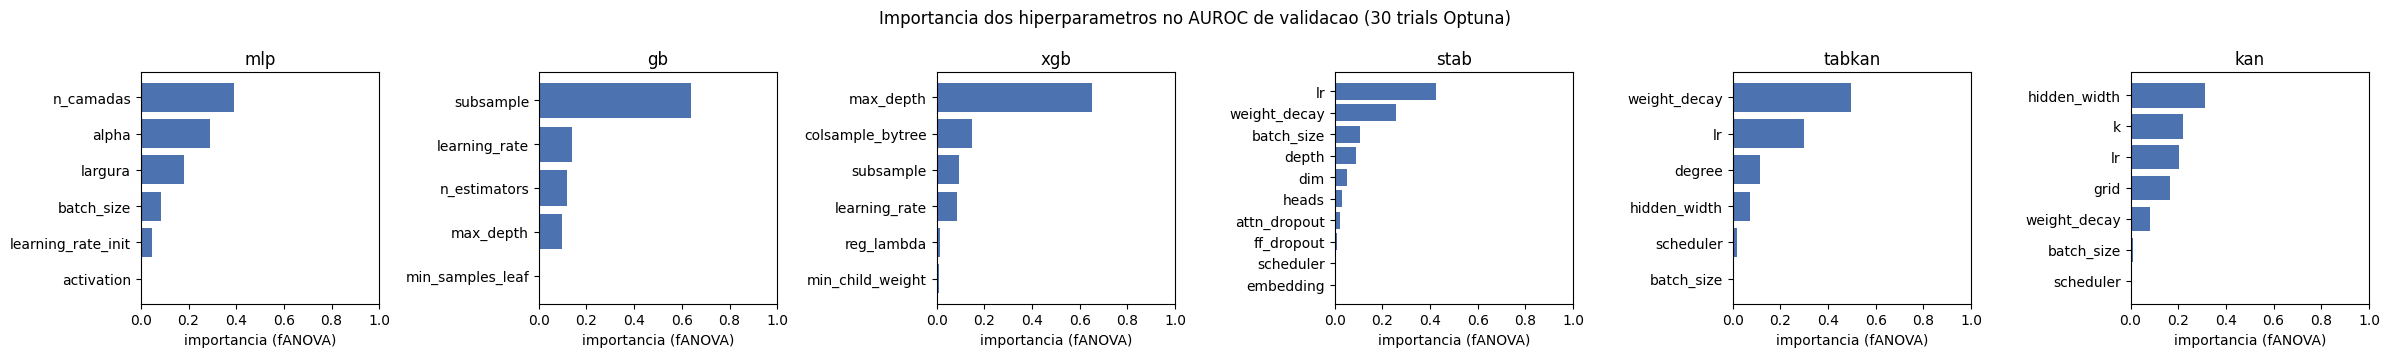

[ok] grafico_importancias


In [20]:
import matplotlib.pyplot as plt

def grafico_importancias():
    algs = [a for a in ALGORITMOS if (TABLES_DIR / f"optuna_importancia_{a}.csv").exists()]
    fig, eixos = plt.subplots(1, len(algs), figsize=(4 * len(algs), 3.6), squeeze=False)
    for ax, alg in zip(eixos[0], algs):
        imp = pd.read_csv(TABLES_DIR / f"optuna_importancia_{alg}.csv").sort_values("importancia")
        ax.barh(imp["parametro"], imp["importancia"], color="#4C72B0")
        ax.set_title(alg); ax.set_xlim(0, 1); ax.set_xlabel("importancia (fANOVA)")
    fig.suptitle(f"Importancia dos hiperparametros no AUROC de validacao ({N_TRIALS} trials Optuna)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "optuna_importancia_hiperparametros.png", dpi=150, bbox_inches="tight")
    plt.show()

    # tabela unica, longa, para a apresentacao
    pd.concat([pd.read_csv(TABLES_DIR / f"optuna_importancia_{a}.csv").assign(algoritmo=a) for a in algs]) \
      .to_csv(TABLES_DIR / "optuna_importancia_todos_algoritmos.csv", index=False)

rodar("grafico_importancias", grafico_importancias)


## Avaliação robusta — padrão vs. Optuna, mesmo procedimento para todos

Mesmas 5 partições (sementes 0–4) das rodadas anteriores. Para cada
algoritmo: configuração padrão e melhor configuração do Optuna, ambas
re-treinadas em cada partição. GB/XGBoost padrão aparecem nas duas
codificações (one-hot vs. ordinal) para isolar o efeito da codificação.
`ganho_em_desvios` = ganho de KS dividido pelo desvio entre partições:
abaixo de ~1, o ganho está dentro do ruído.


In [21]:
def fabrica(hp, treinar):
    """Configuracao fixa (padrao ou melhor do Optuna); a semente vira a da particao."""
    def f(Xtr, ytr, Xva, yva, sd):
        prever, _, _ = treinar(replace(hp, seed=sd), Xtr, ytr, Xva, yva)
        return prever
    return f

PADROES = {"mlp": MLPHyperparams(), "gb": GradientBoostingHyperparams(), "xgb": XGBoostHyperparams(),
           "stab": STabHyperparams(), "tabkan": TabKANHyperparams(), "kan": KANHyperparams()}

def _comparar(r, alg, a, b):
    pa, pb = r.loc[a], r.loc[b]
    ganho = pb["ks_mean"] - pa["ks_mean"]
    return {"algoritmo": alg, "config_a": a, "config_b": b, "ks_a": pa["ks_mean"], "ks_b": pb["ks_mean"],
            "ganho_ks": ganho, "ganho_em_desvios": ganho / max(pa["ks_std"], pb["ks_std"]),
            "auroc_a": pa["auroc_mean"], "auroc_b": pb["auroc_mean"]}

def avaliacao_robusta_optuna():
    if (PROJECT_ROOT / "reports" / "tables" / "avaliacao_robusta_optuna_resumo.csv").exists():
        print("[pulado] avaliacao robusta da rodada Optuna (ja versionada)")
        return
    fabricas, modos = {}, {}
    for alg, (_, treinar, _, modo) in ALGORITMOS.items():
        fabricas[f"{alg}_padrao"], modos[f"{alg}_padrao"] = fabrica(PADROES[alg], treinar), modo
        if alg in BUSCAS:
            fabricas[f"{alg}_optuna"], modos[f"{alg}_optuna"] = fabrica(BUSCAS[alg]["hp"], treinar), modo
    for alg in ("gb", "xgb"):   # efeito isolado da codificacao (mesmo modelo padrao, codificacao das redes)
        fabricas[f"{alg}_padrao_onehot"] = fabrica(PADROES[alg], ALGORITMOS[alg][1])
    otimizados = [f"{a}_optuna" for a in BUSCAS]
    longo = avaliar_multiplas_particoes(df, fabricas, seeds=range(5), incluir_ensemble=False, modos=modos,
                                        ensembles={"ensemble_media_logit_optuna": (otimizados, media_logits)})
    longo.to_csv(TABLES_DIR / "avaliacao_robusta_optuna_por_particao.csv", index=False)
    resumo = resumir(longo)
    resumo.to_csv(TABLES_DIR / "avaliacao_robusta_optuna_resumo.csv", index=False)
    print(resumo.round(4).to_string())

    r = resumo.set_index("modelo")
    pares = [(alg, f"{alg}_padrao", f"{alg}_optuna") for alg in ALGORITMOS]
    pares += [(f"{alg} (codificacao)", f"{alg}_padrao_onehot", f"{alg}_padrao") for alg in ("gb", "xgb")]
    efeito = pd.DataFrame([_comparar(r, *p) for p in pares if p[1] in r.index and p[2] in r.index])
    efeito.to_csv(TABLES_DIR / "efeito_otimizacao_e_codificacao.csv", index=False)
    display(efeito.round(4))

rodar("avaliacao_robusta_optuna", avaliacao_robusta_optuna)


[seed 0] mlp_padrao ks=0.5110 auroc=0.8294
[seed 0] mlp_optuna ks=0.5050 auroc=0.8352
[seed 0] gb_padrao  ks=0.5047 auroc=0.8280
[seed 0] gb_optuna  ks=0.5154 auroc=0.8344
[seed 0] xgb_padrao ks=0.5130 auroc=0.8298
[seed 0] xgb_optuna ks=0.5179 auroc=0.8379
[seed 0] stab_padrao ks=0.5224 auroc=0.8395
[seed 0] stab_optuna ks=0.4968 auroc=0.8334
[seed 0] tabkan_padrao ks=0.5034 auroc=0.8343
[seed 0] tabkan_optuna ks=0.5065 auroc=0.8361
checkpoint directory created: /tmp/kan_ckpt_i5atkxez
saving model version 0.0
[seed 0] kan_padrao ks=0.5063 auroc=0.8344
checkpoint directory created: /tmp/kan_ckpt_k19j5at9
saving model version 0.0
[seed 0] kan_optuna ks=0.5080 auroc=0.8300
[seed 0] gb_padrao_onehot ks=0.5242 auroc=0.8320
[seed 0] xgb_padrao_onehot ks=0.5193 auroc=0.8320
[seed 1] mlp_padrao ks=0.5281 auroc=0.8402
[seed 1] mlp_optuna ks=0.5404 auroc=0.8418
[seed 1] gb_padrao  ks=0.5212 auroc=0.8379
[seed 1] gb_optuna  ks=0.5266 auroc=0.8418
[seed 1] xgb_padrao ks=0.5205 auroc=0.8370
[seed 

,algoritmo,config_a,config_b,ks_a,ks_b,ganho_ks,ganho_em_desvios,auroc_a,auroc_b
0,mlp,mlp_padrao,mlp_optuna,0.5272,0.5295,0.0023,0.1590,0.8405,0.8432
1,gb,gb_padrao,gb_optuna,0.5192,0.5289,0.0097,0.5182,0.8382,0.8426
2,xgb,xgb_padrao,xgb_optuna,0.5267,0.5354,0.0087,0.4846,0.8396,0.8438
3,stab,stab_padrao,stab_optuna,0.5354,0.5324,-0.0029,-0.1438,0.8447,0.8427
4,tabkan,tabkan_padrao,tabkan_optuna,0.5308,0.5273,-0.0035,-0.1993,0.8432,0.8436
5,kan,kan_padrao,kan_optuna,0.5299,0.5295,-0.0003,-0.0204,0.8436,0.8420
6,gb (codificacao),gb_padrao_onehot,gb_padrao,0.5208,0.5192,-0.0016,-0.0862,0.8393,0.8382
7,xgb (codificacao),xgb_padrao_onehot,xgb_padrao,0.5274,0.5267,-0.0007,-0.0334,0.8411,0.8396


[ok] avaliacao_robusta_optuna


## Salvando os resultados da rodada Optuna

Mesma rotina da rodada 2, para a branch `results/churn-otimizacao-optuna`.
Arquivo que já existir no repositório é mantido como está (nunca sobrescrito).


In [22]:
if RODADA_3_CONCLUIDA:
    print("[pulado] salvamento da rodada 3 (ja versionada)")
else:
    pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
                 columns=["modelo", "erro"]).to_csv(TABLES_DIR / "otimizacao_optuna_falhas.csv", index=False)
    print("Falhas:", FALHAS or "nenhuma")
    salvar_saida("results/churn-otimizacao-optuna", "results_churn_otimizacao_optuna",
                 "results: busca Optuna e avaliacao robusta (Kaggle)")


Falhas: nenhuma
Zip gerado: /kaggle/working/results_churn_otimizacao_optuna.zip
Resultados enviados para a branch results/churn-otimizacao-optuna.


# Rodada 4 — o que influenciou de verdade

A rodada 3 mostrou que nem o Optuna nem a codificação das árvores moveram o
KS além do ruído entre partições (ganho máximo: GB, +0.010 = 0.5 desvio).
E a busca varre uma faixa estreita: em TabKAN/KAN os 30 trials ficaram todos
dentro de ~0.003 de AUROC de validação. A importância fANOVA divide essa
variação entre os parâmetros **mesmo quando ela é só ruído de semente** — por
isso, sozinha, ela não diz o que importa.

Esta rodada não treina modelos novos para competir; ela mede o tamanho
de cada efeito contra a régua certa:

1. **Ruído de semente vs. variação paramétrica** — a melhor configuração de
   cada algoritmo é re-treinada com 5 sementes na mesma partição. Se o desvio
   do AUROC entre os 30 trials for parecido com o desvio só por semente, os
   hiperparâmetros (na faixa buscada) não importam mais que o acaso.
2. **Contexto do TabPFN** (com vs. sem as duplicatas do oversampling) em 5
   partições — único fator das rodadas anteriores que ainda só tinha sido
   visto em uma partição.
3. **Tabela única de fatores**, com **teste pareado** nas 5 partições
   (diferença de KS partição a partição, t de Student com 4 graus de
   liberdade). Comparação pareada só entre modelos da mesma avaliação
   (mesmas partições, mesmo hardware, mesma execução).


In [ ]:
import json
from scipy import stats
from churn_telecom.models.tabpfn import TabPFNHyperparams, treinar_tabpfn, prever_tabpfn

TABELAS_REPO = PROJECT_ROOT / "reports" / "tables"
HP_CLASSES = {"mlp": MLPHyperparams, "gb": GradientBoostingHyperparams, "xgb": XGBoostHyperparams,
              "stab": STabHyperparams, "tabkan": TabKANHyperparams, "kan": KANHyperparams}

def ler_tabela(nome):
    # desta execucao, se existir; senao, a ja versionada
    return pd.read_csv(TABLES_DIR / nome if (TABLES_DIR / nome).exists() else TABELAS_REPO / nome)

def ja_versionada(nome):
    if (TABELAS_REPO / nome).exists():
        print(f"[pulado] {nome} ja versionada")
        return True
    return False

def hp_optuna(alg):
    """Melhor configuracao da busca da rodada 3, lida do metadata.json salvo."""
    mid = f"{alg}_churn_optuna{N_TRIALS}trials_auroc_validacao_{CODIFICACAO[ALGORITMOS[alg][3]]}"
    for base in (RESULTS_DIR, RESULTS_REPO):
        p = base / mid / "metadata.json"
        if p.exists():
            hp = json.loads(p.read_text(encoding="utf-8"))["hyperparameters"]
            if alg == "mlp":
                hp["hidden_layer_sizes"] = tuple(hp["hidden_layer_sizes"])
            return HP_CLASSES[alg](**hp)
    raise FileNotFoundError(mid)


## 1. Ruído de semente vs. variação paramétrica

`razao` = desvio do AUROC entre os 30 trials ÷ desvio só por semente (melhor
configuração, 5 sementes). Razão perto de 1 → a busca variou o resultado
tanto quanto trocar a semente. `otimismo_selecao` = AUROC do melhor trial −
média das sementes da mesma configuração: quanto o "melhor trial" deve à sorte.


In [ ]:
N_SEMENTES_RUIDO = 5

def ruido_semente():
    if ja_versionada("ruido_semente_vs_hiperparametros.csv"):
        return
    linhas, pontos = [], {}
    for alg, (_, treinar, _, modo) in ALGORITMOS.items():
        Xtr, Xva, _ = DADOS[modo]
        hp = hp_optuna(alg)
        aucs = []
        for k in range(N_SEMENTES_RUIDO):
            prever, _, _ = treinar(replace(hp, seed=SEED + 1 + k), Xtr, y_train, Xva, y_val)
            aucs.append(auroc(y_val, prever(Xva)))
        trials = ler_tabela(f"optuna_trials_{alg}.csv")
        v = trials.loc[trials["state"] == "COMPLETE", "value"].to_numpy()
        dp_semente = float(np.std(aucs, ddof=1))
        linhas.append({"algoritmo": alg, "auroc_trials_desvio": v.std(ddof=1), "auroc_trials_amplitude": v.max() - v.min(),
                       "auroc_sementes_desvio": dp_semente,
                       "razao": v.std(ddof=1) / dp_semente if dp_semente > 1e-9 else np.inf,  # inf: treino deterministico
                       "auroc_melhor_trial": v.max(), "auroc_melhor_config_media_sementes": float(np.mean(aucs)),
                       "otimismo_selecao": v.max() - float(np.mean(aucs))})
        pontos[alg] = (v, np.array(aucs))
        print(linhas[-1])
    tabela = pd.DataFrame(linhas)
    tabela.to_csv(TABLES_DIR / "ruido_semente_vs_hiperparametros.csv", index=False)
    display(tabela.round(4))

    fig, ax = plt.subplots(figsize=(9, 4))
    rng = np.random.default_rng(0)
    for i, (alg, (v, aucs)) in enumerate(pontos.items()):
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=14, color="#4C72B0", alpha=0.6,
                   label="30 trials Optuna" if i == 0 else None)
        ax.scatter(np.full(len(aucs), i + 0.3), aucs, s=18, color="#DD8452", marker="D",
                   label="melhor config, 5 sementes" if i == 0 else None)
    ax.set_xticks(range(len(pontos)), list(pontos))
    ax.set_ylabel("AUROC de validacao")
    ax.set_title("Variacao por hiperparametros (azul) vs. so por semente (laranja)")
    ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "ruido_semente_vs_hiperparametros.png", dpi=150, bbox_inches="tight")
    plt.show()

rodar("ruido_semente", ruido_semente)


## 2. Contexto do TabPFN em 5 partições

Rodadas 1–2 (partição única): contexto com as duplicatas do oversampling
KS 0.497; sem duplicatas 0.519. Aqui o mesmo par em 5 partições. A correção
de prior não entra: ela é monotônica, não muda KS nem AUROC.


In [ ]:
def f_tabpfn(sem_duplicatas):
    def f(Xtr, ytr, Xva, yva, sd):
        if sem_duplicatas:
            # ponytail: remove copias exatas (as do oversampling); as poucas linhas repetidas
            # do proprio dataset tambem caem — desprezivel perto das ~1650 copias do oversampling
            _, idx = np.unique(Xtr, axis=0, return_index=True)
            idx = np.sort(idx)
            Xtr, ytr = Xtr[idx], ytr[idx]
        m = treinar_tabpfn(Xtr, ytr, TabPFNHyperparams(device=device, n_estimators=8, versao="v2", seed=sd))
        return lambda X: prever_tabpfn(m, X)
    return f

def robusta_tabpfn_contexto():
    if ja_versionada("avaliacao_robusta_tabpfn_contexto_por_particao.csv"):
        return
    longo = avaliar_multiplas_particoes(df, {"tabpfn_contexto_oversample": f_tabpfn(False),
                                             "tabpfn_contexto_sem_duplicatas": f_tabpfn(True)},
                                        seeds=range(5), incluir_ensemble=False)
    longo.to_csv(TABLES_DIR / "avaliacao_robusta_tabpfn_contexto_por_particao.csv", index=False)
    print(resumir(longo).round(4).to_string())

rodar("robusta_tabpfn_contexto", robusta_tabpfn_contexto)


## 3. Tabela única de fatores (teste pareado nas 5 partições)

Para cada fator: diferença de KS `b − a` partição a partição; `ic95` é o
intervalo de confiança de 95% da diferença média (t com 4 g.l.).
**Efeito real** só quando o intervalo não cruza o zero.


In [ ]:
FATORES = [
    # (fator, tabela por particao, a, b)
    ("algoritmo: GB -> STab (configs padrao)", "avaliacao_robusta_optuna_por_particao.csv", "gb_padrao", "stab_padrao"),
    ("algoritmo: MLP -> STab (configs padrao)", "avaliacao_robusta_optuna_por_particao.csv", "mlp_padrao", "stab_padrao"),
    *[(f"hiperparametros (Optuna): {a}", "avaliacao_robusta_optuna_por_particao.csv", f"{a}_padrao", f"{a}_optuna")
      for a in ("mlp", "gb", "xgb", "stab", "tabkan", "kan")],
    ("codificacao arvores: GB onehot -> ordinal", "avaliacao_robusta_optuna_por_particao.csv", "gb_padrao_onehot", "gb_padrao"),
    ("codificacao arvores: XGB onehot -> ordinal", "avaliacao_robusta_optuna_por_particao.csv", "xgb_padrao_onehot", "xgb_padrao"),
    ("ajuste manual STab (embedding/parada/plateau)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "stab_original", "stab_melhorado"),
    ("ajuste manual TabKAN (parada/plateau)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "tabkan_original", "tabkan_melhorado"),
    ("ajuste manual XGB (regularizacao + early stopping)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "xgb_original", "xgb_melhorado"),
    ("bagging de 5 sementes (STab)", "avaliacao_robusta_modelos_melhorados_por_particao.csv", "stab_melhorado", "stab_melhorado_bagging"),
    ("ensemble: melhor modelo isolado -> media logit", "avaliacao_robusta_optuna_por_particao.csv", "xgb_optuna", "ensemble_media_logit_optuna"),
    ("contexto TabPFN: com -> sem duplicatas", "avaliacao_robusta_tabpfn_contexto_por_particao.csv",
     "tabpfn_contexto_oversample", "tabpfn_contexto_sem_duplicatas"),
]

def comparar_pareado(longo, a, b):
    w = longo.pivot_table(index="seed", columns="modelo", values="ks")[[a, b]].dropna()
    d = (w[b] - w[a]).to_numpy()
    n = len(d)
    meia = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return {"ks_a": w[a].mean(), "ks_b": w[b].mean(), "ganho_ks": d.mean(),
            "ic95_inf": d.mean() - meia, "ic95_sup": d.mean() + meia, "n_particoes": n,
            "veredito": "efeito real" if (d.mean() - meia > 0 or d.mean() + meia < 0) else "dentro do ruido"}

def tabela_fatores():
    if ja_versionada("fatores_que_influenciam_ks.csv"):
        return
    linhas = []
    for fator, tabela, a, b in FATORES:
        try:
            linhas.append({"fator": fator, "config_a": a, "config_b": b, **comparar_pareado(ler_tabela(tabela), a, b)})
        except (FileNotFoundError, KeyError) as e:
            print(f"sem dados para '{fator}': {e}")
    fatores = pd.DataFrame(linhas).sort_values("ganho_ks")
    fatores.to_csv(TABLES_DIR / "fatores_que_influenciam_ks.csv", index=False)
    display(fatores.round(4))

    fig, ax = plt.subplots(figsize=(9, 0.42 * len(fatores) + 1.2))
    cores = ["#55A868" if v == "efeito real" else "#8C8C8C" for v in fatores["veredito"]]
    ax.barh(fatores["fator"], fatores["ganho_ks"], color=cores,
            xerr=[fatores["ganho_ks"] - fatores["ic95_inf"], fatores["ic95_sup"] - fatores["ganho_ks"]],
            error_kw={"elinewidth": 1, "capsize": 3})
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("ganho de KS no teste (media de 5 particoes, IC 95% pareado)")
    ax.set_title("O que influenciou o KS (verde: efeito real; cinza: dentro do ruido)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fatores_que_influenciam_ks.png", dpi=150, bbox_inches="tight")
    plt.show()

rodar("tabela_fatores", tabela_fatores)


## Salvando os resultados da rodada 4

Branch `results/churn-fatores-influencia`; arquivo já versionado é mantido.


In [ ]:
pd.DataFrame([{"modelo": k, "erro": v} for k, v in FALHAS.items()],
             columns=["modelo", "erro"]).to_csv(TABLES_DIR / "fatores_influencia_falhas.csv", index=False)
print("Falhas:", FALHAS or "nenhuma")
salvar_saida("results/churn-fatores-influencia", "results_churn_fatores_influencia",
             "results: ruido de semente, contexto TabPFN e tabela de fatores (Kaggle)")
